<a href="https://colab.research.google.com/github/BrownEyeGirl/postcards-from-my-jungle/blob/main/image_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# • + ₊ ˚ ཐི⋆XerFlies! - Image Generation⋆ཋྀ ˚ ₊ +

Training images from a combined dataset with butterflies and pnemonia x-rays

**Before you start:** Runtime → Change runtime type → choose a **GPU** (A100 or G4 is fastest; T4 works but is slower).
Then run the cells **from top to bottom**.

## 0. Setup




In [ ]:
# Colab sometimes ships a version of `torchao` that breaks `diffusers`. This cell checks for that problem and fixes it.
# If it prints *“Fixing a package conflict…”*, the session restarts and Colab shows a “crashed” message. **That is expected.** Just run this cell again, then continue.
try:
    from diffusers import UNet2DModel
    print("diffusers is ready ✓")
except Exception as e:
    print("Fixing a package conflict, the session will restart…")
    import subprocess, os
    subprocess.run(["pip", "uninstall", "-y", "torchao"])
    os.kill(os.getpid(), 9)

## 1. Presets

My presets make highly trained low res images. This is done because the dataset is complex: I trained it with pnemonia lung x-rays and butterfly images.

In [ ]:
import torch

IMAGE_SIZE    = 32    # images are 32x32 pixels (32 trains faster, 64 trains moderately fast, 128 is much slower)
NUM_IMAGES    = 500    # how many photos to train on
BATCH_SIZE    = 32      # images per training step
NUM_EPOCHS    = 160      # passes through the whole dataset
LEARNING_RATE = 2e-4    # peak learning rate
WARMUP_STEPS  = 500     # steps to ramp the learning rate up from zero
EMA_DECAY     = 0.999   # how smooth the averaged (EMA) weights are
PREVIEW_EVERY = 5      # show sample cats every N epochs
SEED          = 1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = device.type == "cuda" and torch.cuda.is_bf16_supported()

torch.manual_seed(SEED)
print("Device:", torch.cuda.get_device_name() if device.type == "cuda" else "CPU (training will be very slow!)")
print("bfloat16 speed-up:", "on" if USE_BF16 else "off (this GPU doesn’t support it)")

Device: CPU (training will be very slow!)
bfloat16 speed-up: off (this GPU doesn’t support it)


## 2. Datasets
This model uses butterfly images and pnemonia chest x-rays to train. <br><br>`mmenendezg/pneumonia_x_ray` contains pnemonia chest x-rays on black backgrounds. <br>
`huggan/smithsonian_butterflies_subset` contains butterfly images on a white background. <br>

Loading butterfly dataset...


README.md:   0%|          | 0.00/609 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.65k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237MB            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4187 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1045 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/624 [00:00<?, ? examples/s]

Successfully combined datasets! Total hybrid training images: 300


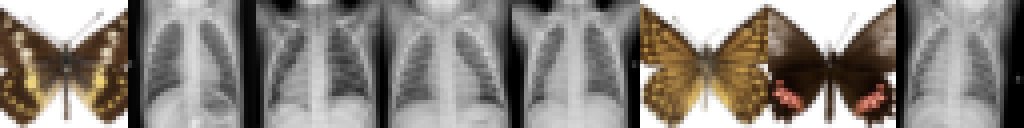

In [ ]:
import torch
from datasets import load_dataset, Dataset, Features, Image as DImage
from torchvision import transforms
from diffusers.utils import make_image_grid
from PIL import Image
import numpy as np

print("Loading butterfly dataset...")
butterfly_ds = load_dataset("huggan/smithsonian_butterflies_subset", split="train")

print("Loading chest x-ray dataset...")
xray_ds = load_dataset("mmenendezg/pneumonia_x_ray", split="train")

combined_images = []

# Load up to 150 butterfly images
for i in range(min(150, len(butterfly_ds))):
    try:
        img = butterfly_ds[i]["image"].convert("RGB")
        combined_images.append(img)
    except Exception as e:
        continue

# Load up to 150 chest x-ray images
for i in range(min(150, len(xray_ds))):
    try:
        raw_img = xray_ds[i]["image"]
        if not isinstance(raw_img, Image.Image):
            img = Image.open(raw_img).convert("RGB")
        else:
            img = raw_img.convert("RGB")
        combined_images.append(img)
    except Exception as e:
        continue

# Combine datasets under one class of target images
dataset = Dataset.from_dict({"image": combined_images}, features=Features({"image": DImage()}))
dataset = dataset.shuffle(seed=SEED)
print(f"Successfully combined datasets! Total hybrid training images: {len(dataset)}")

preprocess = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),            # short side → IMAGE_SIZE, keeps proportions
    transforms.CenterCrop(IMAGE_SIZE),        # cut a square from the centre
    transforms.RandomHorizontalFlip(),        # mirror half of them (free extra data)
    transforms.ToTensor(),                    # pixels → numbers in [0, 1]
    transforms.Normalize([0.5], [0.5]),       # [0, 1] → [-1, 1], the range diffusion works in
])

def transform(batch):
    return {"pixel_values": [preprocess(img.convert("RGB")) for img in batch["image"]]}

dataset.set_transform(transform)

# Set num_workers=0 to prevent multiprocessing crashes on CPU
train_dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=min(BATCH_SIZE, len(dataset)),
    shuffle=True,
    drop_last=True,
    num_workers=0,
    collate_fn=lambda b: torch.stack([x["pixel_values"] for x in b]),
)

def to_pil(batch, size=128):
    """Tensors in [-1, 1] → list of (enlarged) images for display."""
    batch = ((batch.clamp(-1, 1) + 1) / 2 * 255).byte().cpu()
    return [Image.fromarray(img.permute(1, 2, 0).numpy()).resize((size, size), Image.NEAREST)
            for img in batch]

# Look at what the model will learn from
make_image_grid(to_pil(next(iter(train_dataloader))[:8]), rows=1, cols=8)

## 3. Model, noise schedule, optimizer

- **UNet**: the network that looks at a noisy image and predicts the noise in it.
- **Noise scheduler**: decides how much noise is added at each of the 1,000 steps. The cosine schedule (`squaredcos_cap_v2`) destroys small images more gradually than the default.
- **EMA**: a slowly updated average of the model’s weights. It is smoother than the raw weights and gives cleaner images.
- **Learning-rate schedule**: warm up for the first steps, then slowly decrease.

In [ ]:
from diffusers import UNet2DModel, DDPMScheduler
from diffusers.training_utils import EMAModel
from diffusers.optimization import get_cosine_schedule_with_warmup

def make_model():
    return UNet2DModel(
        sample_size=IMAGE_SIZE,
        in_channels=3,
        out_channels=3,
        layers_per_block=2,
        block_out_channels=(64, 128, 256, 512),
        down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
        up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
    ).to(device)

model = make_model()
print(f"Model size: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million parameters")

noise_scheduler = DDPMScheduler(num_train_timesteps=1000, beta_schedule="squaredcos_cap_v2")

ema = EMAModel(model.parameters(), decay=EMA_DECAY)
ema.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
total_steps = len(train_dataloader) * NUM_EPOCHS
lr_scheduler = get_cosine_schedule_with_warmup(optimizer, WARMUP_STEPS, total_steps)
print(f"Training steps: {total_steps}")

## Generate the Xerflies
**DDIM** for generating because it reaches similar quality in 50–100 steps instead of 1,000.

In [ ]:
from diffusers import DDIMScheduler

@torch.no_grad()
def generate(unet, n=8, steps=100, seed=0):
    sampler = DDIMScheduler.from_config(noise_scheduler.config)   # same noise schedule as training
    sampler.set_timesteps(steps)
    generator = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 3, IMAGE_SIZE, IMAGE_SIZE, generator=generator, device=device)  # start: pure noise
    was_training = unet.training
    unet.eval()
    for t in sampler.timesteps:
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_BF16):
            noise_pred = unet(x, t).sample                         # predict the noise
        x = sampler.step(noise_pred.float(), t, x).prev_sample     # remove a little of it
    unet.train(was_training)
    return to_pil(x)

def preview_with_ema(n=8, steps=50):
    """Generate with the smoothed (EMA) weights, then switch back to the training weights."""
    ema.store(model.parameters())
    ema.copy_to(model.parameters())
    images = generate(model, n=n, steps=steps)
    ema.restore(model.parameters())
    return make_image_grid(images, rows=1, cols=n)

## 5. Train

Steps:
1. take photo from xerflies (xray and butterflies) dataset
2. add a random amount of noise, ask the model to predict that noise
3. correct it based on how wrong it was.

Every few epochs sample xerflies will be generated from the noise with the EMA weights.

**Timing (roughly):** about 10–20 minutes on an A100 or G4, 40+ minutes on a T4. To go faster, lower `NUM_EPOCHS` or `NUM_IMAGES`, or set `IMAGE_SIZE = 32`.

In [14]:
import torch.nn.functional as F
from tqdm.auto import tqdm
from IPython.display import display

losses = []
model.train()

for epoch in range(NUM_EPOCHS):
    progress = tqdm(train_dataloader, desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}", leave=False)
    for clean_images in progress:
        clean_images = clean_images.to(device, non_blocking=True)

        # 1. Add a random amount of noise to each image
        noise = torch.randn_like(clean_images)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                                  (clean_images.shape[0],), device=device).long()
        noisy_images = noise_scheduler.add_noise(clean_images, noise, timesteps)

        # 2. Ask the model to predict that noise
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_BF16):
            noise_pred = model(noisy_images, timesteps).sample
        loss = F.mse_loss(noise_pred.float(), noise)

        # 3. Learn from the mistake
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # avoid sudden huge updates
        optimizer.step()
        lr_scheduler.step()
        ema.step(model.parameters())                              # update the smoothed copy

        losses.append(loss.item())
        progress.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = sum(losses[-len(train_dataloader):]) / len(train_dataloader)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}: average loss {epoch_loss:.4f}")

    if (epoch + 1) % PREVIEW_EVERY == 0 or epoch + 1 == NUM_EPOCHS:
        display(preview_with_ema())

Epoch 1/80:   0%|          | 0/9 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 6. Training loss graph

The loss drops fast, then flattens.

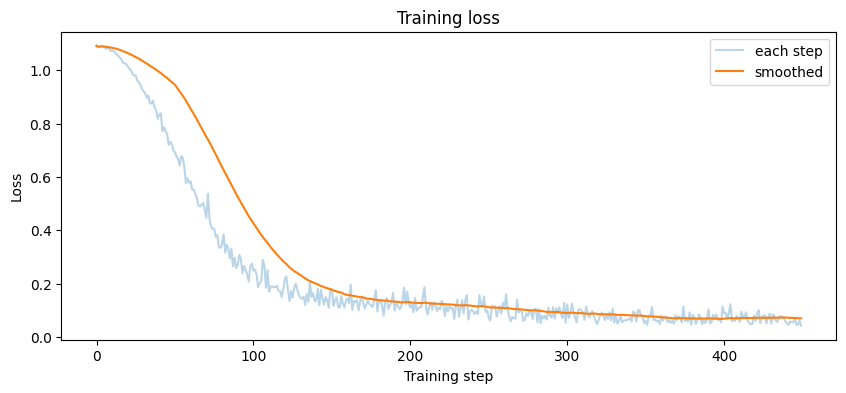

In [ ]:
from matplotlib import pyplot as plt

def smooth(values, k=50):
    return [sum(values[max(0, i - k):i + 1]) / len(values[max(0, i - k):i + 1]) for i in range(len(values))]

plt.figure(figsize=(10, 4))
plt.plot(losses, alpha=0.3, label="each step")
plt.plot(smooth(losses), label="smoothed")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Training loss")
plt.legend()
plt.show()

## 7. Save the model

We save the **EMA weights**, the smoothed version that generates cleaner images.

To keep the file on your own device after the session ends, uncomment the Google Drive lines.

In [15]:
ema.copy_to(model.parameters())                   # replace training weights with the EMA weights
torch.save(model.state_dict(), "xerfly_diffusion_ema.pth")
print("Saved xerfly_diffusion_ema.pth")

# from google.colab import drive
# drive.mount("/content/drive")
# torch.save(model.state_dict(), "/content/drive/MyDrive/ai/xerfly_diffusion_ema.pth")

KeyboardInterrupt: 

## 8. Generate Xerflies

Generate Xerflies! Load the saved weights from my trained xerfly_diffusion model to generate your own xerflies.

Seed: different xerflies <br>
Steps: quality of xerflies

Downloading...
From (original): https://drive.google.com/uc?id=1-FL3U_OqKBTuCDXVqSdYu7IjMXKVeYlU
From (redirected): https://drive.google.com/uc?id=1-FL3U_OqKBTuCDXVqSdYu7IjMXKVeYlU&confirm=t&uuid=5454b6cf-a557-4820-91b8-7d4e015f62d7
To: /content/xerfly_diffusion_ema_downloaded.pth
100%|██████████| 253M/253M [00:03<00:00, 76.0MB/s]


Model loaded successfully!
Generating hybrid images...


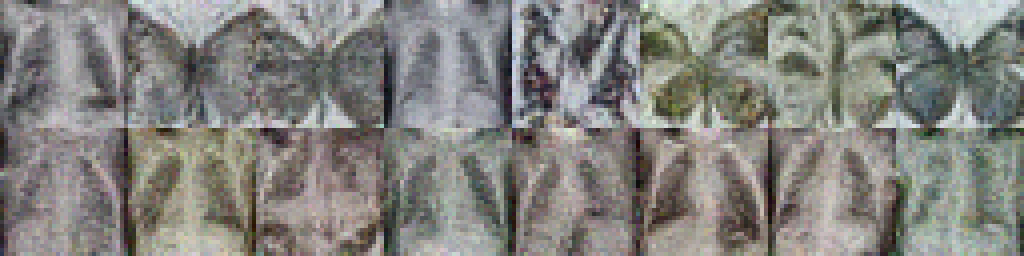